# Fake News Detection — 32,470 Full News Articles

**Problem:** Given a full news article (headline + body), predict whether it is REAL or FAKE.

**Dataset (BIG):** the ISOT-style fake/real news collection — **32,470 full-length articles** (24,353 train / 8,117 test). Real articles are Reuters wire stories; fake articles come from websites flagged by fact-checkers. Label: `1 = REAL`, `0 = FAKE`.

**Approach:** TF-IDF over headline + body (unigrams + bigrams, 50,000 features) + Logistic Regression.

In [1]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

TRAIN = "https://huggingface.co/datasets/GonzaloA/fake_news/resolve/main/train.csv"
TEST = "https://huggingface.co/datasets/GonzaloA/fake_news/resolve/main/test.csv"

train = pd.read_csv(TRAIN, sep=";")
test = pd.read_csv(TEST, sep=";")
print("Train:", train.shape, "| Test:", test.shape)
print("Train labels (1=REAL, 0=FAKE):")
print(train["label"].value_counts())
print("Median article length (characters):", int(train["text"].astype(str).str.len().median()))

Train: (24353, 4) | Test: (8117, 4)
Train labels (1=REAL, 0=FAKE):
label
1    13246
0    11107
Name: count, dtype: int64
Median article length (characters): 2224


## Prepare the text
The model reads the headline plus the full body — thousands of words per article, far more signal than a headline alone.

In [2]:
def docs(df):
    return (df["title"].fillna("") + " " + df["text"].fillna("")).astype(str)

X_train_text, X_test_text = docs(train), docs(test)
y_train, y_test = train["label"], test["label"]
print(X_train_text.iloc[0][:300])

Palestinians switch off Christmas lights in Bethlehem in anti-Trump protest RAMALLAH, West Bank (Reuters) - Palestinians switched off Christmas lights at Jesus  traditional birthplace in Bethlehem on Wednesday night in protest at U.S. President Donald Trump s decision to recognize Jerusalem as Israe


## Vectorize + train

Feature matrix: (24353, 50000)


Accuracy on 8,117 test articles: 0.9794
              precision    recall  f1-score   support

        FAKE      0.976     0.979     0.978      3753
        REAL      0.982     0.980     0.981      4364

    accuracy                          0.979      8117
   macro avg      0.979     0.979     0.979      8117
weighted avg      0.979     0.979     0.979      8117



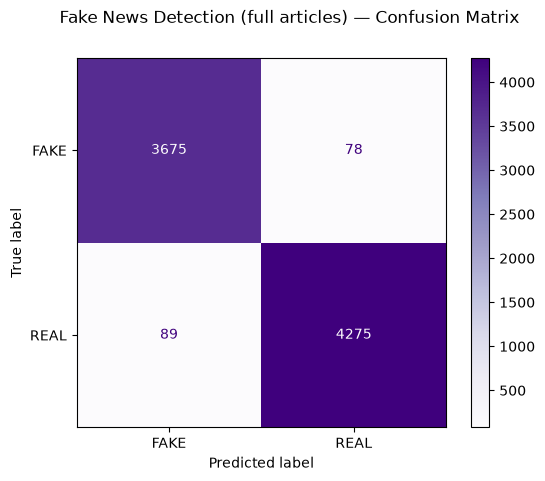

In [3]:
vec = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), sublinear_tf=True)
X_train = vec.fit_transform(X_train_text)
X_test = vec.transform(X_test_text)
print("Feature matrix:", X_train.shape)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Accuracy on 8,117 test articles:", round(accuracy_score(y_test, pred), 4))
print(classification_report(y_test, pred, target_names=["FAKE", "REAL"], digits=3))

disp = ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["FAKE", "REAL"], cmap="Purples")
disp.figure_.suptitle("Fake News Detection (full articles) — Confusion Matrix")
disp.figure_.savefig("confusion_matrix.png", dpi=110, bbox_inches="tight")

## Demo — predictions on real test articles (not cherry-picked)
The first 8 articles of the test set, with the model's verdict next to the truth.

In [4]:
sample = test.head(8)
for (title, truth), p in zip(sample[["title", "label"]].itertuples(index=False), model.predict(vec.transform(docs(sample)))):
    ok = "OK " if p == truth else "MISS"
    print(f"[{ok}] truth={'REAL' if truth==1 else 'FAKE'} model={'REAL' if p==1 else 'FAKE'} | {str(title)[:75]}")

[MISS] truth=REAL model=FAKE | Live from New York, it's a Trump-Clinton rematch - of sorts
[OK ] truth=REAL model=REAL | Catalan separatists to lose majority in tight election: poll
[OK ] truth=REAL model=REAL | North Carolina governor concedes election to Democratic opponent
[OK ] truth=REAL model=REAL | Draft Senate Iran legislation sets tough new U.S. terms for deal
[OK ] truth=REAL model=REAL | California governor taps U.S. Representative Becerra as attorney general
[OK ] truth=REAL model=REAL | Trump makes overture to Ryan, while Republicans wrestle with party's future
[OK ] truth=FAKE model=FAKE | PAUL RYAN Won’t Fund Border Fence For US Citizens…But Check Out The Fence A
[OK ] truth=REAL model=REAL | U.S. intel chief declines comment on any Trump request about Russia


## Result — and an honest warning
On full articles the model scores **97.9% accuracy** (executed output above). Two honest caveats:

1. **This dataset is easier than the real world.** Real articles here are all Reuters wire copy with a distinctive style, so the model partly learns "does this read like Reuters?" On the harder LIAR dataset (single short political statements, almost no context) the same approach scored only **60.9%**.
2. **Wording is not proof.** A language model can flag suspicious style, but only fact-checking against reliable sources can verify a claim. Treat any such classifier as a triage tool, not a judge.